# 1.0 Property model (M3)
Recipe → density → stress at 10% strain. Each model is tested by leaving one lab (dataset) out, so it is scored on a lab it has never seen.

**Fold error** = how far off a prediction typically is, as a factor: 1.0 is perfect, 2.0 means typically half or double the real value.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from mycodemo.config import FIGURES_DIR, REPORTS_DIR
from mycodemo.property_data import main as build_table
from mycodemo.property_model import TwoStepModel, leave_one_lab_out, score, training_rows, within_lab_check

table = build_table()  # also saves data/processed/property_table.csv
table.groupby("dataset_id")[["stress_mpa", "density_kg_m3"]].count()

2026-10-09 12:43:14.247 | INFO     | mycodemo.config:<module>:11 - PROJ_ROOT path is: /home/sylas/Desktop/mycodemo


Saved 211 rows to /home/sylas/Desktop/mycodemo/data/processed/property_table.csv


,stress_mpa,density_kg_m3
dataset_id,,
d004,58,58
d005,32,42
d006,54,0
d007,23,23
d016,4,6
d017,0,6
d023,0,12


## Density vs stress
Both axes are logarithmic. If the points of all labs fall on one straight band, density explains most of the strength.

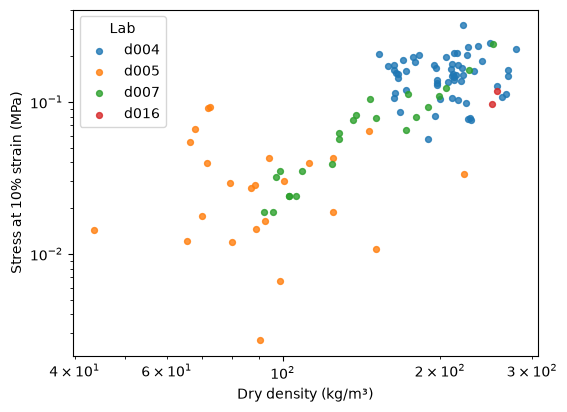

In [2]:
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
both = table.dropna(subset=["stress_mpa", "density_kg_m3"])
fig, ax = plt.subplots(figsize=(6, 4.5))
for lab, g in both.groupby("dataset_id"):
    ax.scatter(g["density_kg_m3"], g["stress_mpa"], label=lab, s=18, alpha=0.8)
ax.set(xscale="log", yscale="log", xlabel="Dry density (kg/m³)", ylabel="Stress at 10% strain (MPa)")
ax.legend(title="Lab")
fig.savefig(FIGURES_DIR / "m3_density_vs_stress.png", dpi=150, bbox_inches="tight")

In [3]:
model = TwoStepModel().fit(training_rows(table))
print(f"stress ∝ density^{model.stress.coef_[0]:.2f}")

stress ∝ density^1.73


## How much do blocks of the same recipe vary?
Density separates labs and recipes, but within one lab denser blocks are not reliably stronger. This spread is the band the app should show around any estimate.

In [4]:
raw = table[(table["measurement_type"] == "raw") & table["stress_mpa"].notna()]
groups = raw.groupby(["dataset_id", "species_name", "plant_name", "spawn_pct_wt"], dropna=False)["stress_mpa"]
spread = groups.agg(["count", "mean", "std"]).query("count >= 3")
spread["cv_pct"] = (100 * spread["std"] / spread["mean"]).round(0)
spread.groupby("dataset_id")["cv_pct"].median()  # typical replicate spread per lab, in %

dataset_id
d004    28.5
d005    66.5
d006    23.0
d016    15.0
Name: cv_pct, dtype: float64

## Leave one lab out
- `mean_baseline`: the average stress of the other labs
- `recipe_direct`: species + substrate straight to stress
- `two_step`: species + substrate → density → stress (usable before growing)
- `measured_density`: stress from the measured density (only known after harvest; a reference, not a plan)

In [5]:
pred = leave_one_lab_out(table)
results = score(pred)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
results.to_csv(REPORTS_DIR / "m3_results.csv", index=False)
results.pivot(index="held_out_lab", columns="model", values="fold_error")

model,mean_baseline,measured_density,recipe_direct,two_step
held_out_lab,,,,
d004,3.38,1.55,4.16,3.52
d005,2.93,2.22,2.80,2.85
d006,2.35,NaN,1.45,1.44
d007,2.06,1.29,1.96,1.75
d016,1.92,1.77,2.29,2.27


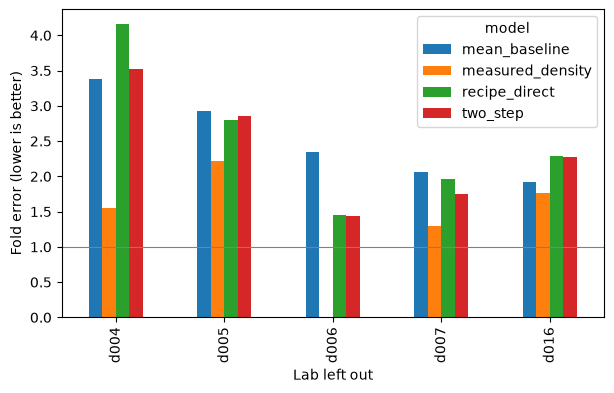

In [6]:
ax = results.pivot(index="held_out_lab", columns="model", values="fold_error").plot.bar(figsize=(7, 4))
ax.axhline(1, color="grey", lw=0.8)
ax.set(ylabel="Fold error (lower is better)", xlabel="Lab left out")
ax.figure.savefig(FIGURES_DIR / "m3_fold_error.png", dpi=150, bbox_inches="tight")

## Does fibre preparation matter? (inside d005)
d005 (Elsacker 2019) varied how the fibres were prepared: dust, chopped, loose, long tow, and pressed while growing (100 -> 80 mm). The other labs keep preparation fixed, so this can only be tested inside d005.

Each d005 sample is left out once and predicted from the rest:
- `recipe_only`: species + substrate group
- `recipe_plus_processing`: also particle size class and pre-compressed (yes/no)

The two PFL specimens with unknown treatment (flag CF7) are left out.

In [7]:
within = score(within_lab_check(table, "d005"))
within.to_csv(REPORTS_DIR / "m3_within_d005.csv", index=False)
within

,held_out_lab,model,n_rows,fold_error
0,d005,mean_baseline,30,1.91
1,d005,recipe_only,30,1.86
2,d005,recipe_plus_processing,30,1.66


In [8]:
d005 = training_rows(table).query("dataset_id == 'd005' and stress_mpa.notna()")
d005.groupby(["pre_compressed", "particle_size_class"])["stress_mpa"].agg(["count", "median"]).round(3)

count  median
pre_compressed particle_size_class               
0.0            2.0                      3   0.043
               3.0                     16   0.017
               4.0                      5   0.034
1.0            3.0                      6   0.064

## Check on chitosan-coated samples (d007)
These were not used for training.

In [ ]:
coated = table[table["coated"]]
coated.assign(predicted=model.predict_stress(coated))[["sample_id", "stress_mpa", "predicted"]]

## Notes
Write what you see here: which model beats the baseline, and for which lab.